# SYDE 522 - Lecture 5 (PCA)
## Author: Charbel Azzi



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

%matplotlib inline

### Create toy data


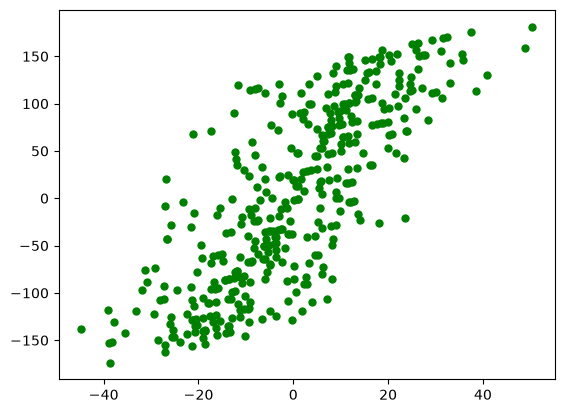

In [2]:
n = 400

# generate data along random line (y = ax + b)
a = np.random.randint(1, 10)
b = np.random.randint(1, 10)
x1 = np.random.randint(-20, 20, size=(n))

y1 = a*x1 + b

# add random noise
noise = np.random.rand(n) * np.random.randint(-35,35,size=n)

#make the noise orthogonal to the line y=mx+c and add it.
# x=x1 + noise*a/np.sqrt(1+a**2)
# y=y1 + noise/np.sqrt(1+a**2)
x=x1 + noise
y=y1 + noise

# vizualize
plt.plot(x, y, 'o', color='green', markersize=5)

## Iterative algorithm for PCA

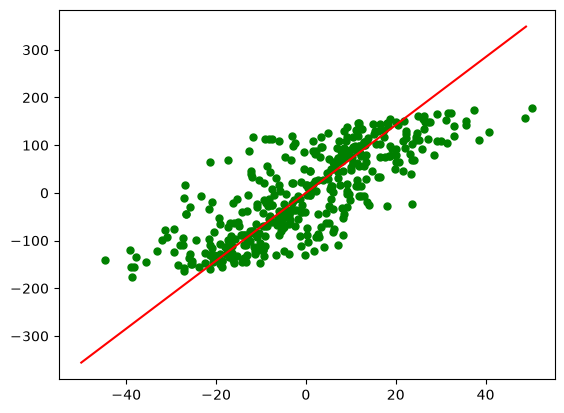

In [3]:
data = np.stack((x.T, y.T), axis=-1)

# IMPORTANT: CENTERING SO WE DON'T DO THIS BACK and FORTH!!!
# centering the data i.e, mean = (0, 0)
data = data - np.mean(data, axis=0)

def unit_vector(angle):
    angle_rad = np.deg2rad(angle)
    return np.array([[np.cos(angle_rad)], [np.sin(angle_rad)]])


def draw_line(ang, rng=[-50, 50], color='red'):
    m = np.tan(np.deg2rad(ang))
    x = np.arange(rng[0], rng[1])
    y = x * m
    plt.plot(x, y, '-', linewidth=1.5, color=color)


max_var_ang = np.argmax([np.var(np.dot(data, unit_vector(i))) for i in range(180)])
min_var_ang = np.argmin([np.var(np.dot(data, unit_vector(i))) for i in range(180)])

plt.plot(data[:, 0], data[:, 1], 'o', color='green', markersize=5)
draw_line(max_var_ang)
#draw_line(min_var_ang, rng=[-30, 30], color='blue')
#plt.axis([-50, 40, -90, 90])

## Better algorithm for PCA
### Diagonlizing the covariance matrix

#### STEP 1: Find covariance matrix

In [4]:
covmat = np.cov(data.T)

covmat

array([[ 276.54144625, 1237.93647749],
       [1237.93647749, 8857.2390526 ]])

#### STEP 2: Eigenvalue decomposition


In [5]:
eig_vals, eig_vecs = np.linalg.eig(covmat)

eig_vals, eig_vecs

(array([ 101.5146129 +0.j, 9032.26588594+0.j]),
 array([[-0.9901524 +0.j, -0.13999364+0.j],
        [ 0.13999364+0.j, -0.9901524 +0.j]]))

#### STEP 3: Sort eigenvalues and eigenvectors

So here we get 2x2 eigen vectors i.e. 2 PCs since we have 2D which means for each eigen vector we have its 2D value decomposition --> Pick the one with the highest eigen value (variance) so you have your 1D PCs to project on

In [6]:
sort_idx = np.argsort(eig_vals)[::-1]
sorted_pair = list(zip(eig_vals[sort_idx], eig_vecs[sort_idx]))
sorted_pair

[(np.complex128(9032.265885941517+0j),
  array([ 0.13999364+0.j, -0.9901524 +0.j])),
 (np.complex128(101.51461290481893+0j),
  array([-0.9901524 +0.j, -0.13999364+0.j]))]

PCA via Singular Value Decomposition: helps computing large covariance matrix and SVD computes eigenvectors faster

In [7]:
u, s, v = np.linalg.svd(data - data.mean(axis=0))
v

array([[-0.13999364, -0.9901524 ],
       [ 0.9901524 , -0.13999364]])

#### Results

We have 2 principle components - pick the one with the highest variance and project from 2D to 1D

In [8]:
best_ang = np.abs(np.rad2deg(np.arctan(sorted_pair[0][1][1]/sorted_pair[0][1][0])))

print("PCA angle (better algo):\t {0}".format(best_ang))
print("PCA angle (iterative algo):\t {0}".format(max_var_ang))

TypeError: ufunc 'rad2deg' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [ ]:
plt.plot(data[:, 0], data[:, 1], 'o', color='green', markersize=5)
draw_line(best_ang)
#plt.axis([-50, 40, -90, 90])

## Using Sklearn Implementation

Take a toy example of 3 4D points. Apply the built in functions from sklearn.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2) # try 1 and 3

X = [[1,2,3,4],[2,4,6,8],[1,3,5,7],[10,11,20,21]]

fit will fit the model to map data (get the mean, covariance, eigenvectors and eigen values). Then returns the n_components eigenvectors i.e. the n_components PCs

In [ ]:
pca.fit(X)


print(pca.components_)

Now we actually map the data - this projects the data using the projection matrix defined by your PCs/eigenvectors

In [ ]:
pca.transform(X)

Or we can do both "at once"


In [ ]:
x_projected = pca.fit_transform(X)
print(x_projected)

Reconstruct the projected points back into 4D

In [ ]:
pca.inverse_transform(x_projected) # transforms data back to original space

## Digits Visualization

1797 images of handwritten digits. Each datapoint/image is a 8x8 image of a digit.

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

ind = np.random.randint(0,digits.data.shape[0])
plt.figure(figsize=(2,2))
plt.imshow(digits.images[ind], cmap='binary', interpolation='nearest')
plt.title(str(digits.target[ind]))
plt.axis('off')
plt.axis('equal')
plt.show()

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(2)  # project from 64 to 2 dimensions
projected = pca.fit_transform(digits.data)
print(digits.data.shape)
print(projected.shape)

In [ ]:
plt.figure(figsize=(10, 7))
plt.scatter(projected[:, 0], projected[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5,
            cmap=plt.cm.get_cmap('tab20', 10))
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar()

### Choosing the number of components
A vital part of using PCA in practice is the ability to estimate how many components are needed to describe the data. This can be determined by looking at the cumulative explained variance ratio as a function of the number of components:

In [ ]:
pca = PCA().fit(digits.data)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

This curve quantifies how much of the total, 64-dimensional variance is contained within the first  N  components. For example, we see that with the digits dataset, the first 10 components contain approximately 75% of the variance, while you need around 40 components to describe close to 100% of the variance.

Here we see that our 2D projection loses a lot of information (as measured by the explained variance) and that we'd need about 20 components to retain 90% of the variance. Looking at this plot for a high-dimensional dataset can help you understand the level of redundancy present in multiple observations.

## Denoising Images

If we add random noise to the data it should not contribute to high variance dimensions. Therefore, PCA can help in denoising the data.

In [ ]:
def plot_digits(data):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))
plot_digits(digits.data)

The seed is given an integer value to ensure that the results of pseudo-random generation are reproducible. By re-using a seed value, the same sequence should be reproducible from run to run as long as multiple threads are not running. Reproducibility is a very important concept that ensures that anyone who re-runs the code gets the exact same outputs.

In [ ]:
np.random.seed(42)
noisy = np.random.normal(digits.data, 4)
plot_digits(noisy)

In [ ]:
# use 50% of real dimensions components
# PCA(n_components) will select the number of components such that the amount of variance that needs to be explained is greater than the percentage specified by n_components - if you give an integer >=1 then it will choose that integer to be your number of PCs
# PCA fit will fit data (via covariance, mean, etc) to find the principal components

pca = PCA(0.5).fit(noisy) # if a float is given then the algorithm will maximize the variance to  be > 50%
components = pca.transform(noisy) # After fitting the model apply the dimensionalty reduction
print(components.shape)
filtered = pca.inverse_transform(components) # transforms data back to original space
plot_digits(filtered)

## PCA: Face Images Search Example

The original images are 250 x 250 pixels, but the default slice and resize (0.5) arguments reduce them to 62 x 47. I will resize them further resize them to 0.4 to 50 x 37.

In [ ]:
from sklearn.datasets import fetch_lfw_people
#import logging
# Display progress logs on stdout
#logging.basicConfig(level=logging.INFO, format='%(asctime)s %(message)s')
lfw_people = fetch_lfw_people(resize=0.4)

In [ ]:
lfw_people.data.shape

In [ ]:
plt.imshow(lfw_people.images[-10], cmap='Greys_r')
plt.axis('off')

### Run PCA

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=100)

Let's fit a linear model with 100 PCs

In [ ]:
pca.fit(lfw_people.data)

### Eigen faces

Eigen face is pricipal components after applying PCA on data-set. Intuitively, each eigen face represent a feature set such that their linear combinations can be used to construct any other faces.

In [ ]:
plt.figure(figsize=(10, 10))
for i, component in enumerate(pca.components_):
    plt.subplot(10, 10, i+1)
    plt.imshow(component.reshape(lfw_people.images[-10].shape), cmap='Greys_r')
    plt.axis('off')

### Creating a face mixture of Donald Trump + Paul Martin

In [ ]:
rf = np.zeros((50, 37)) + pca.mean_.reshape(50, 37)
components = pca.transform(lfw_people.data) # Fit the PCA with X and apply the dimensionality reduction on X
print(components.shape)

In [ ]:
def find_person(name_substr):
    for i, name in enumerate(lfw_people.target_names):
        if name_substr in name:
            print(i, name)

find_person('Donald Trump')
#find_person('Trudeau')
#find_person('Harper')
find_person('George W Bush')

In [ ]:
# Donald Trump + Paul Martin
trumps = lfw_people.data[lfw_people.target == 1405]
bush = lfw_people.data[lfw_people.target == 1871]

np.random.shuffle(trumps)
np.random.shuffle(bush)

plt.figure()
plt.imshow(pca.inverse_transform(pca.transform(bush[0:1])).reshape(50, 37),
           cmap='Greys_r')
plt.axis('off')

plt.figure()
plt.imshow(pca.inverse_transform(pca.transform(trumps[0:1])).reshape(50, 37),
           cmap='Greys_r')
plt.axis('off')

plt.figure()
plt.imshow(pca.inverse_transform((pca.transform(trumps[0:1])
                                  + pca.transform(bush[0:1]))/2.).reshape(50, 37),
           cmap='Greys_r')
plt.axis('off')

### Constructing an external face

In [ ]:
def upload_files():
  from google.colab import files
  uploaded = files.upload()
  for k, v in uploaded.items():
    open(k, 'wb').write(v)
  return list(uploaded.keys())

me = upload_files()

In [ ]:
from skimage.io import imread
from skimage.transform import resize

im = imread('cazzi.png')
im = np.mean(im, axis=2)
im = resize(im, (50, 37))

plt.imshow(im, cmap='Greys_r')
plt.axis('off')

In [ ]:
lcp = pca.transform(im.ravel().reshape(1, -1))
plt.imshow(pca.inverse_transform(lcp).reshape(50, 37), cmap='Greys_r')
plt.axis('off')

### Querying the closest faces

K-Dimensional Tree is a binary search tree for organizing points in a K-Dimensional space. Here it is used for quick nearest-neighbor lookup

In [ ]:
from scipy.spatial import cKDTree

# make a query tree indexing all the PCA reduced faces
pres_query = cKDTree(pca.transform(lfw_people.data))

# query external face (3 closest matches)
_, idxs = pres_query.query(lcp, k=3)
idxs

In [ ]:
plt.figure(figsize=(10,5))

# plots the matches
plt.subplot(1, 4, 1)
plt.imshow(im, cmap='Greys_r')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(lfw_people.images[idxs[0][0]], cmap='Greys_r')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(lfw_people.images[idxs[0][1]], cmap='Greys_r')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(lfw_people.images[idxs[0][2]], cmap='Greys_r')
plt.axis('off')

#### Searching existing people

Pick an image at random from the dataset and query its 10 closest matches. The closest match should be itself.

In [ ]:
sidx = np.random.randint(0, len(lfw_people.images))
lcp = pca.transform(lfw_people.data[sidx].reshape(1, -1))

n_query = 10
# query external face (n_query closest matches)
_, t_idxs = pres_query.query(lcp, k=n_query)

print(t_idxs)
plt.figure(figsize=(20,10))


# plots the matches
plt.subplot(1, n_query+1, 1)
plt.imshow(lfw_people.images[sidx], cmap='Greys_r')
plt.axis('off')

for i in range(0, n_query):
    plt.subplot(1, n_query+1, i+2)
    plt.imshow(lfw_people.images[t_idxs[0][i]], cmap='Greys_r')
    plt.axis('off')